# ДЗ 3. Предсказание стоимости недвижимости

**Задача:** по признакам объявления предсказать `price`. Метрика — **MAE в исходных единицах цены**, меньше лучше.

Используем линейную регрессию. Сравниваем заполнение пропусков, масштабы, One-Hot и частотное кодирование, полиномиальные признаки и преобразование целевой переменной. Ridge приведён только для сравнения; итоговая модель выбирается **среди вариантов `LinearRegression`**. Деревья и бустинг не используются.

Линейность означает линейность по обучаемым коэффициентам: $\hat z=b+\sum_jw_j\phi_j(x)$. При логарифмировании цели $z=\log(price)$ прогноз цены равен $\exp(\hat z)$; это уже не линейная функция исходных признаков, но обучаемый алгоритм остаётся линейной регрессией.

**Запуск:** положить `train.csv`, `test.csv`, `sample_submission.csv` в папку `data` рядом с ноутбуком или рядом с самим ноутбуком, затем выполнить все ячейки сверху вниз. В конце появится `submission.csv`. Нужны Python 3.11+ и библиотеки из `requirements.txt`.

In [1]:
import os
os.environ['OMP_NUM_THREADS'] = '2'
os.environ['OPENBLAS_NUM_THREADS'] = '2'
from pathlib import Path
import time
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import (OneHotEncoder, StandardScaler,
                                   MinMaxScaler, PolynomialFeatures)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error
from threadpoolctl import threadpool_limits
threadpool_limits(limits=2)
SEED = 42
pd.set_option('display.max_columns', 30)
DATA_DIR = Path('data') if Path('data/train.csv').exists() else Path('.')
train = pd.read_csv(DATA_DIR / 'train.csv')
test = pd.read_csv(DATA_DIR / 'test.csv')
sample = pd.read_csv(DATA_DIR / 'sample_submission.csv')
assert 'price' in train and 'price' not in test
assert train.id.is_unique and test.id.is_unique
assert not set(train.id).intersection(test.id)
assert list(test.columns) == list(train.drop(columns='price').columns)
assert list(sample.columns) == ['id', 'price']
assert len(sample) == len(test) and set(sample.id) == set(test.id)
assert train.price.notna().all() and train.price.gt(0).all()
print('Train:', train.shape, 'Test:', test.shape)
display(train.head())

Fontconfig error: No writable cache directories


Train: (100000, 25) Test: (100000, 24)


,id,date,street_id,build_tech,floor,area,rooms,balcon,metro_dist,g_lift,n_photos,kw1,kw2,kw3,kw4,kw5,kw6,kw7,kw8,kw9,kw10,kw11,kw12,kw13,price
0,0,2011-1,560,NaN,2,59,3,0,30.0,1.0,5,0,1,0,0,0,0,0,0,0,0,0,0,0,4510000
1,1,2011-1,667,NaN,10,50,2,1,25.0,NaN,1,0,1,0,0,0,0,0,0,0,0,0,0,0,13231000
2,2,2011-1,90,0.0,1,48,2,0,25.0,0.0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,2008000
3,3,2011-1,94,1.0,3,62,3,1,30.0,NaN,3,0,1,0,0,0,0,0,0,0,0,0,0,0,12680000
4,4,2011-1,232,0.0,3,60,3,0,25.0,NaN,3,0,1,0,0,0,0,0,0,0,0,0,0,0,3335000


## 1. Первичный анализ

`id` — идентификатор строки: исключаем из признаков, сохраняем для ответа. `street_id` и `build_tech` — категории: разность их кодов не имеет количественного смысла. `kw1`–`kw13` — бинарные признаки объявления. `date` сначала преобразуем в настоящую дату: строковая сортировка неправильно упорядочивает месяцы без ведущего нуля.

Пропуски не заполняем на всей таблице заранее: статистики будут обучаться внутри Pipeline только на обучающей части.

,Доля пропусков
g_lift,0.29992
build_tech,0.29735
metro_dist,0.04896


,price,area,floor,rooms,metro_dist
count,1.000000e+05,100000.00000,100000.000000,100000.000000,95104.000000
mean,5.138396e+06,52.25343,5.267680,2.118680,22.154431
std,4.187469e+06,17.79250,3.905558,0.829688,8.286241
min,4.480000e+05,29.00000,1.000000,1.000000,0.000000
25%,2.644000e+06,40.00000,2.000000,1.000000,15.000000
50%,4.090000e+06,52.00000,4.000000,2.000000,25.000000
75%,6.281000e+06,60.00000,7.000000,3.000000,30.000000
max,8.054800e+07,217.00000,25.000000,6.000000,30.000000


Полных дубликатов: 0
Train: 2011-01-01 — 2012-12-01
Test: 2012-03-01 — 2013-12-01


,size,median
month,,
2011-01-01,5578,3684500.0
2011-02-01,5546,3642000.0
2011-03-01,5482,3703000.0
2011-04-01,5671,3739000.0
2011-05-01,5568,3840500.0
2011-06-01,5582,3907500.0
2011-07-01,5500,3919500.0
2011-08-01,5546,4019000.0
2011-09-01,5583,4092000.0


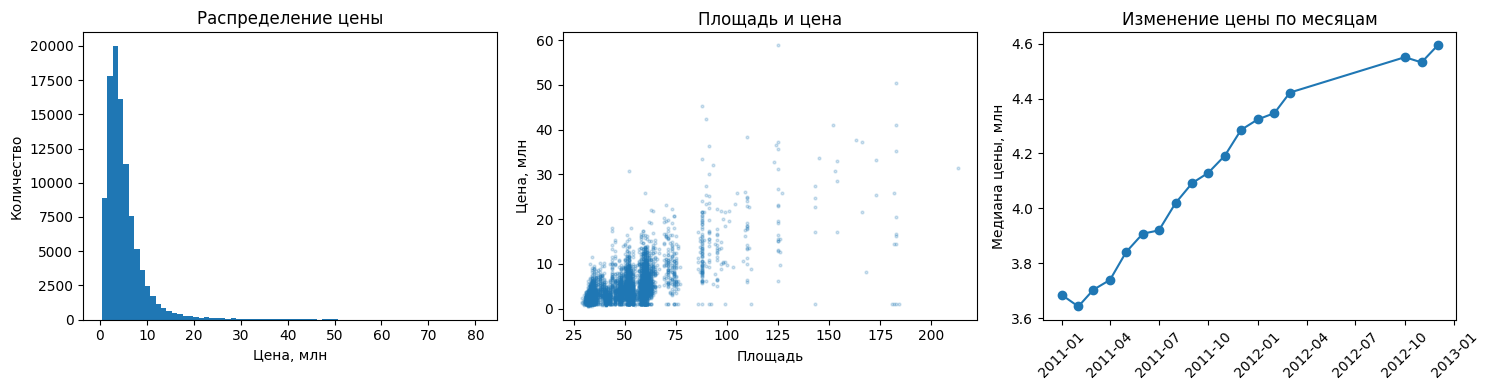

In [2]:
dates = pd.to_datetime(train['date'], format='%Y-%m')
test_dates = pd.to_datetime(test['date'], format='%Y-%m')
missing = train.isna().mean().sort_values(ascending=False)
display(missing[missing > 0].rename('Доля пропусков').to_frame())
display(train[['price', 'area', 'floor', 'rooms', 'metro_dist']].describe())
print('Полных дубликатов:', train.duplicated().sum())
print('Train:', dates.min().date(), '—', dates.max().date())
print('Test:', test_dates.min().date(), '—', test_dates.max().date())
monthly = train.assign(month=dates).groupby('month')['price'].agg(['size', 'median'])
display(monthly)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(train.price / 1e6, bins=70)
axes[0].set(xlabel='Цена, млн', ylabel='Количество', title='Распределение цены')
axes[1].scatter(train.area.iloc[::20], train.price.iloc[::20] / 1e6, s=4, alpha=.2)
axes[1].set(xlabel='Площадь', ylabel='Цена, млн', title='Площадь и цена')
axes[2].plot(monthly.index, monthly['median'] / 1e6, marker='o')
axes[2].set(ylabel='Медиана цены, млн', title='Изменение цены по месяцам')
axes[2].tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

## 2. Проверка качества без утечки

В файлах есть особенность: train включает октябрь–декабрь 2012 года, а test начинается в марте 2012 года и продолжается в 2013-м. Это согласуется со строковой сортировкой дат, но не доказывает способ подготовки файлов. Поэтому не считаем порядок строк корректным календарным порядком.

Фиксируем разбиение по **настоящим датам**:
- обучение вариантов: всё до октября 2012;
- validation для сравнения вариантов: октябрь и ноябрь 2012;
- контрольная выборка: декабрь 2012. Открываем её после выбора модели и не меняем модель по её результату.

Промежуток без обучающих месяцев между мартом и октябрём сохраняем: он помогает проверить экстраполяцию во времени. Результат validation используется для выбора и не является независимой оценкой. Декабрь — отдельная контрольная оценка; она также не гарантирует результат на более далёком 2013 годе. Ответов для конкурсного test нет.

В конце обучаем выбранную конфигурацию на всех размеченных строках, включая контрольный месяц, и прогнозируем test.

In [3]:
fit_mask = dates < '2012-10-01'
valid_mask = (dates >= '2012-10-01') & (dates < '2012-12-01')
audit_mask = dates >= '2012-12-01'
assert (fit_mask.astype(int) + valid_mask.astype(int) + audit_mask.astype(int)).eq(1).all()
assert dates[fit_mask].max() < dates[valid_mask].min()
assert dates[valid_mask].max() < dates[audit_mask].min()
X = train.drop(columns='price')
y = train.price
X_fit, y_fit = X.loc[fit_mask], y.loc[fit_mask]
X_valid, y_valid = X.loc[valid_mask], y.loc[valid_mask]
X_audit, y_audit = X.loc[audit_mask], y.loc[audit_mask]
print('Обучение / validation / контроль:', len(X_fit), len(X_valid), len(X_audit))
baseline_mae = mean_absolute_error(y_valid, np.full(len(y_valid), y_fit.median()))
print(f'MAE медианного baseline на validation: {baseline_mae:,.0f}')

Обучение / validation / контроль: 83295 11116 5589
MAE медианного baseline на validation: 2,863,145


## 3. Признаки и частотное кодирование

Создаём признаки без использования цен: порядковый номер месяца, логарифм площади, площадь на комнату, первый этаж. Дополнительно проверяем комбинации `rooms × area`, `floor × build_tech`, `rooms × build_tech`: One-Hot для комбинации позволяет линейной модели иметь отдельный коэффициент для сочетания значений. Пропуск технологии в таких комбинациях обозначаем отдельной категорией.

Время задаём линейным трендом, корнем, логарифмом либо двумя линейными участками с заранее заданной границей через год. Это сравниваем на validation; будущие цены не используем. Все варианты имеют ограничения при экстраполяции.

Частотный encoder запоминает частоты только при `fit`. Новая категория получает 0. Он находится внутри Pipeline, поэтому validation и test не участвуют в расчёте частот.

In [4]:
class FeatureBuilder(BaseEstimator, TransformerMixin):
    def __init__(self, trend='linear'):
        self.trend = trend

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        out = X.drop(columns=['id', 'price'], errors='ignore').copy()
        d = pd.to_datetime(out.pop('date'), format='%Y-%m')
        t = (d.dt.year - 2011) * 12 + d.dt.month - 1
        out['time'] = t.astype(float)
        if self.trend == 'sqrt':
            out['time'] = np.sqrt(t + 1)
        elif self.trend == 'log':
            out['time'] = np.log1p(t)
        elif self.trend == 'piecewise':
            out['time_after_year'] = np.maximum(t - 11, 0)
        out['log_area'] = np.log(out['area'])
        out['area_per_room'] = out['area'] / out['rooms']
        out['first_floor'] = (out['floor'] == 1).astype(int)
        out['rooms_area'] = out.rooms.astype(str) + '_' + out.area.astype(str)
        tech = out.build_tech.fillna(-1).astype(str)
        out['floor_tech'] = out.floor.astype(str) + '_' + tech
        out['rooms_tech'] = out.rooms.astype(str) + '_' + tech
        return out

class FrequencyEncoder(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        values = np.asarray(X)
        self.maps_ = [pd.Series(values[:, i]).value_counts(normalize=True)
                      for i in range(values.shape[1])]
        return self

    def transform(self, X):
        values = np.asarray(X)
        return np.column_stack([
            pd.Series(values[:, i]).map(mapping).fillna(0).to_numpy()
            for i, mapping in enumerate(self.maps_)
        ])

# Небольшая проверка поведения на неизвестной категории.
enc_demo = FrequencyEncoder().fit(np.array([['A'], ['A'], ['B']]))
assert np.allclose(enc_demo.transform(np.array([['A'], ['new']])).ravel(), [2/3, 0])

## 4. Pipeline и ColumnTransformer

Числовая ветка: `SimpleImputer(median, add_indicator=True)` → scaler. Полиномиальная ветка (когда включена): imputer → `PolynomialFeatures(degree=2)` → scaler, только для логарифма площади и площади на комнату. Ограничиваем число взаимодействий, чтобы не раздувать матрицу редкими сочетаниями ключевых слов.

Категориальная ветка: заполнение модой или отдельным значением `-1` → One-Hot / частоты. One-Hot безопасно обрабатывает неизвестные категории через `handle_unknown="ignore"`. Для целочисленных этажа, комнат и других дискретных признаков отдельно проверяем One-Hot: он допускает нелинейную зависимость цены от уровня признака, сохраняя линейность модели по коэффициентам.

`LabelEncoder` предназначен для меток классов и для непрерывной цены не нужен. `OrdinalEncoder` подходит для категорий с обоснованным порядком; у кодов улиц такого порядка нет, поэтому его здесь не используем.

Логарифмирование цели — проверяемая гипотеза о мультипликативной зависимости цены. Оно не гарантирует уменьшения MAE и не требует поправки на среднее при оценке MAE. Считаем MAE **после обратного преобразования**, а не в логарифмах.

In [5]:
def make_model(target='raw', encoding='onehot', scaler='standard',
               imputation='most_frequent', expanded=False, joint=False,
               poly=False, trend='linear', estimator='ols', alpha=1.0):
    cat_cols = ['street_id', 'build_tech', 'g_lift']
    if expanded:
        cat_cols += ['floor', 'rooms', 'metro_dist', 'balcon', 'n_photos']
    joint_cols = ['rooms_area', 'floor_tech', 'rooms_tech']
    # Только имена столбцов: статистики по validation здесь не вычисляются.
    engineered_cols = list(FeatureBuilder(trend).transform(X_fit.iloc[:1]).columns)
    poly_cols = ['log_area', 'area_per_room'] if poly else []
    num_cols = [c for c in engineered_cols
                if c not in cat_cols + joint_cols + poly_cols]
    scale = StandardScaler if scaler == 'standard' else MinMaxScaler
    numeric = Pipeline([
        ('imputer', SimpleImputer(strategy='median', add_indicator=True)),
        ('scaler', scale())
    ])
    encoder = OneHotEncoder(handle_unknown='ignore') if encoding == 'onehot' else FrequencyEncoder()
    categorical = Pipeline([
        ('imputer', SimpleImputer(strategy=imputation, fill_value=-1)),
        ('encoder', encoder)
    ])
    branches = [('numeric', numeric, num_cols), ('categories', categorical, cat_cols)]
    if joint:
        branches.append(('joint_categories', OneHotEncoder(handle_unknown='ignore'), joint_cols))
    if poly:
        branches.append(('polynomial', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('polynomial', PolynomialFeatures(2, include_bias=False)),
            ('scaler', scale())
        ]), poly_cols))
    regressor = (LinearRegression(tol=1e-6) if estimator == 'ols'
                 else Ridge(alpha=alpha, solver='lsqr', tol=1e-6))
    pipe = Pipeline([
        ('features', FeatureBuilder(trend)),
        ('preprocess', ColumnTransformer(branches, sparse_threshold=1.0)),
        ('regressor', regressor)
    ])
    if target == 'log':
        return TransformedTargetRegressor(regressor=pipe, func=np.log, inverse_func=np.exp)
    return pipe

## 5. Сравнение вариантов

Во всех экспериментах используем одинаковые месяцы. Сравниваем ограниченный набор осмысленных вариантов. В итог допускаем только `LinearRegression`; Ridge — дополнительное сравнение регуляризации. StandardScaler и MinMaxScaler могут давать очень близкий результат для обычного МНК: изменение единиц признаков само по себе не меняет пространство линейных прогнозов. Для Ridge масштаб влияет на регуляризацию.

In [6]:
configs = {
    'OLS: исходная цена': {},
    'OLS: log(price), StandardScaler': {'target': 'log'},
    'OLS: log(price), MinMaxScaler': {'target': 'log', 'scaler': 'minmax'},
    'OLS: частотное кодирование': {'target': 'log', 'encoding': 'frequency'},
    'OLS: отдельная категория пропуска': {'target': 'log', 'imputation': 'constant'},
    'OLS: дискретные признаки OHE': {'target': 'log', 'imputation': 'constant', 'expanded': True},
}
advanced = dict(target='log', imputation='constant', expanded=True, joint=True)
for trend in ['linear', 'sqrt', 'log', 'piecewise']:
    for poly in [False, True]:
        name = f'OLS: сочетания, trend={trend}, poly={poly}'
        configs[name] = dict(advanced, trend=trend, poly=poly)
configs['Ridge: сочетания (только сравнение)'] = dict(advanced, estimator='ridge', alpha=1.0)
rows = [{'model': 'Медиана', 'MAE': baseline_mae, 'seconds': 0.0}]
for name, config in configs.items():
    started = time.perf_counter()
    model = make_model(**config)
    model.fit(X_fit, y_fit)
    prediction = model.predict(X_valid)
    assert np.isfinite(prediction).all()
    score = mean_absolute_error(y_valid, prediction)
    rows.append({'model': name, 'MAE': score, 'seconds': time.perf_counter() - started})
    print(f'{name}: MAE = {score:,.0f}')
results = pd.DataFrame(rows).sort_values('MAE').reset_index(drop=True)
display(results.round({'MAE': 2, 'seconds': 2}))
results.to_csv('validation_results.csv', index=False)
els = results[results.model.str.startswith('OLS:')]
best_name = els.iloc[0]['model']
best_config = configs[best_name].copy()
print('Выбранная модель:', best_name)
print('Настройки:', best_config)
assert best_config.get('estimator', 'ols') == 'ols'
print(f"Улучшение MAE к медиане: {100 * (1 - els.iloc[0]['MAE'] / baseline_mae):.1f}%")

OLS: исходная цена: MAE = 1,199,980


OLS: log(price), StandardScaler: MAE = 848,389


OLS: log(price), MinMaxScaler: MAE = 848,387


OLS: частотное кодирование: MAE = 1,996,675


OLS: отдельная категория пропуска: MAE = 830,539


...

OLS: сочетания, trend=piecewise, poly=False: MAE = 734,856


OLS: сочетания, trend=piecewise, poly=True: MAE = 734,837


Ridge: сочетания (только сравнение): MAE = 734,381


,model,MAE,seconds
0,Ridge: сочетания (только сравнение),734381.22,2.98
1,"OLS: сочетания, trend=piecewise, poly=True",734837.14,3.96
2,"OLS: сочетания, trend=piecewise, poly=False",734856.20,4.05
3,"OLS: сочетания, trend=linear, poly=True",735976.29,3.21
4,"OLS: сочетания, trend=linear, poly=False",735989.22,3.17
5,"OLS: сочетания, trend=sqrt, poly=True",768255.10,3.36
6,"OLS: сочетания, trend=sqrt, poly=False",768277.86,2.90
7,OLS: дискретные признаки OHE,790562.53,1.34
8,OLS: отдельная категория пропуска,830538.56,0.97
9,"OLS: log(price), MinMaxScaler",848386.70,0.77


Выбранная модель: OLS: сочетания, trend=piecewise, poly=True
Настройки: {'target': 'log', 'imputation': 'constant', 'expanded': True, 'joint': True, 'trend': 'piecewise', 'poly': True}
Улучшение MAE к медиане: 74.3%


## 6. Независимая контрольная проверка

Конфигурация зафиксирована. Переобучаем её на всех месяцах до декабря 2012 и один раз оцениваем декабрь. После этой оценки не меняем признаки и параметры. Печатаем ошибки по диапазонам цены, чтобы увидеть, не скрывает ли средняя метрика большие ошибки на дорогих объектах.

Контроль, декабрь 2012: MAE = 791,467
Медианный baseline на контроле: MAE = 2,736,558


,size,mean,median
price_group,,,
"(0.0, 3000000.0]",1445,8.710587e+05,2.146542e+05
"(3000000.0, 6000000.0]",2357,4.235200e+05,3.473785e+05
"(6000000.0, 10000000.0]",1223,8.512264e+05,7.551552e+05
"(10000000.0, inf]",564,1.995647e+06,1.524934e+06


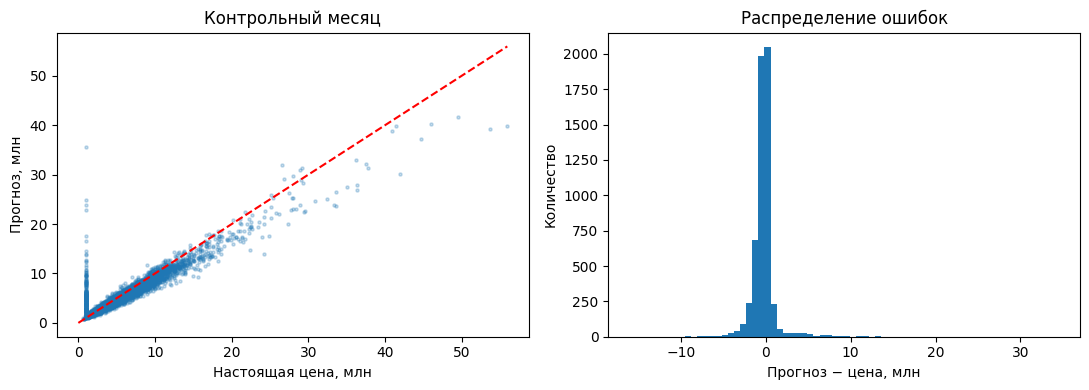

340

In [7]:
development_mask = ~audit_mask
selected = make_model(**best_config)
selected.fit(X.loc[development_mask], y.loc[development_mask])
audit_prediction = selected.predict(X_audit)
audit_mae = mean_absolute_error(y_audit, audit_prediction)
audit_baseline = mean_absolute_error(
    y_audit, np.full(len(y_audit), y.loc[development_mask].median()))
print(f'Контроль, декабрь 2012: MAE = {audit_mae:,.0f}')
print(f'Медианный baseline на контроле: MAE = {audit_baseline:,.0f}')
errors = pd.DataFrame({'price': y_audit, 'prediction': audit_prediction})
errors['absolute_error'] = np.abs(errors.price - errors.prediction)
errors['price_group'] = pd.cut(errors.price, [0, 3e6, 6e6, 10e6, np.inf])
display(errors.groupby('price_group', observed=True).absolute_error.agg(['size', 'mean', 'median']))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(y_audit / 1e6, audit_prediction / 1e6, s=5, alpha=.25)
lim = max(y_audit.max(), audit_prediction.max()) / 1e6
axes[0].plot([0, lim], [0, lim], color='red', linestyle='--')
axes[0].set(xlabel='Настоящая цена, млн', ylabel='Прогноз, млн', title='Контрольный месяц')
axes[1].hist((audit_prediction - y_audit) / 1e6, bins=70)
axes[1].set(xlabel='Прогноз − цена, млн', ylabel='Количество', title='Распределение ошибок')
plt.tight_layout()
plt.show()
metrics = {'best_model': best_name, 'best_config': best_config,
           'validation_mae': float(els.iloc[0]['MAE']),
           'audit_mae': float(audit_mae), 'audit_baseline_mae': float(audit_baseline)}
Path('metrics.json').write_text(json.dumps(metrics, ensure_ascii=False, indent=2), encoding='utf-8')

## 7. Обучение на всех данных и submission

Теперь используем все 100 000 размеченных объявлений. Идентификаторы в ответе располагаем ровно в порядке `sample_submission.csv`, сопоставляя прогнозы по `id`. Не округляем цену до целых и не записываем индекс DataFrame отдельным столбцом. Проверяем отсутствие пропусков, бесконечностей, лишних строк и отрицательных цен.

In [8]:
final_model = make_model(**best_config)
final_model.fit(X, y)
test_prediction = final_model.predict(test)
assert len(test_prediction) == len(test)
assert np.isfinite(test_prediction).all() and (test_prediction > 0).all()
prediction_by_id = pd.Series(test_prediction, index=test.id)
submission = sample[['id']].copy()
submission['price'] = submission.id.map(prediction_by_id)
assert submission.shape == sample.shape
assert submission.id.equals(sample.id)
assert list(submission.columns) == ['id', 'price']
assert submission.notna().all().all()
submission.to_csv('submission.csv', index=False)
check = pd.read_csv('submission.csv')
assert check.id.equals(sample.id) and check.shape == sample.shape
assert np.allclose(check.price, submission.price)
print('Сохранён submission.csv:', submission.shape)
display(submission.head())
display(submission.price.describe())

Сохранён submission.csv: (100000, 2)


,id,price
0,100000,7.065030e+06
1,100001,4.693512e+06
2,100002,3.579086e+06
3,100003,2.918204e+06
4,100004,6.340576e+06


count    1.000000e+05
mean     5.503940e+06
std      4.091890e+06
min      5.873071e+05
25%      3.064640e+06
50%      4.466263e+06
75%      6.608922e+06
max      8.698837e+07
Name: price, dtype: float64

## Выводы

1. Предобработка обучается внутри Pipeline: медианы, масштабы, словари категорий и частоты не получают информации из отложенных строк.
2. Коды улиц обрабатываются как категории; идентификатор объявления исключён. Числа, категории и полиномиальные признаки проходят отдельные ветки ColumnTransformer.
3. Сравнение проводится по MAE в исходных единицах, даже если модель обучается на логарифме цены. Лучшая конфигурация и реальные значения MAE напечатаны выше и сохранены в `metrics.json`.
4. Финальный алгоритм — `LinearRegression`. Сложность добавляется преобразованиями признаков, а не деревьями или бустингом.
5. `submission.csv` содержит предсказания для всех строк test. MAE и место в соревновании неизвестны до внешней проверки. В условии формула score отображается неоднозначно, поэтому здесь не вычисляем предположительный балл.

**Ограничения:** временной тренд приходится продолжать за границы train; будущая динамика может измениться. Редкие/новые сочетания категорий оцениваются менее надёжно. Логарифмирование меняет функцию обучения и не гарантирует оптимальность по MAE. Валидационное сравнение нескольких вариантов делает оценку validation оптимистичной; для этого отдельно оставлен контрольный декабрь.